<a href="https://colab.research.google.com/github/Ariqq16/PCVK_Ganjil_2026/blob/main/P8/Tugas_Praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

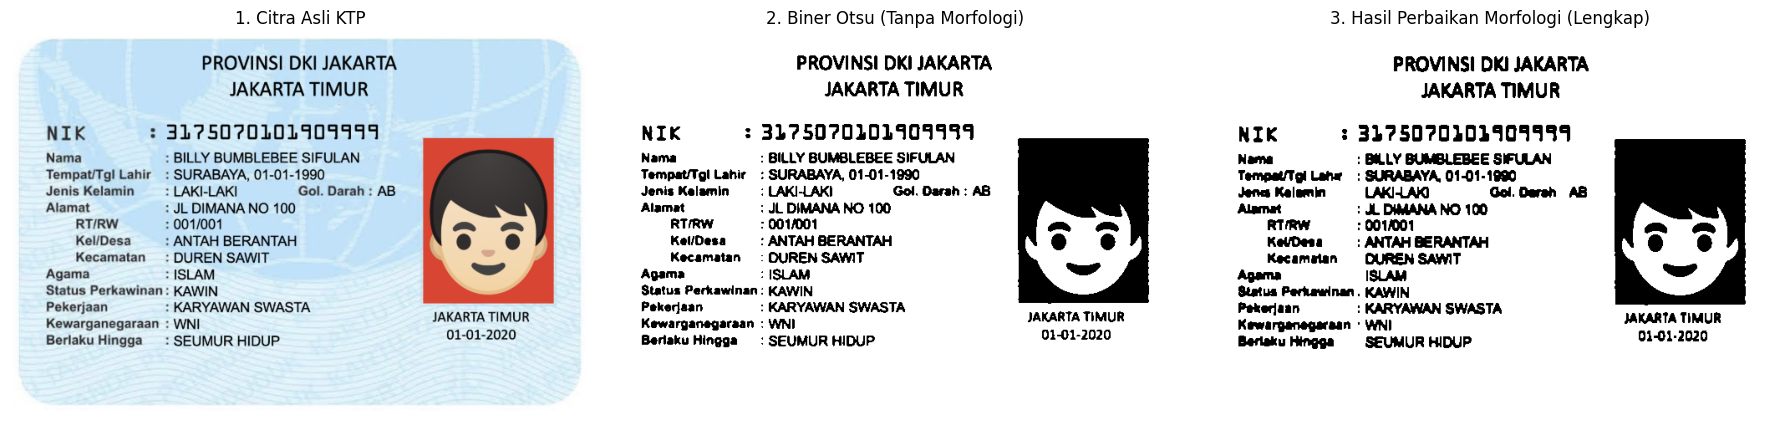

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

BASE_PATH = '/content/drive/MyDrive/PCVK_2026/' # Path folder Colab Anda

path_ktp = os.path.join(BASE_PATH, 'ktp.jpeg')
img_ktp = cv.imread(path_ktp)

if img_ktp is None:
    path_ktp = os.path.join(BASE_PATH, 'ktp_fulan.jpg')
    img_ktp = cv.imread(path_ktp)

if img_ktp is None:
    raise FileNotFoundError("Citra KTP tidak ditemukan di Drive!")

gray = cv.cvtColor(img_ktp, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (3, 3), 0)
_, thresh = cv.threshold(blur, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

kernel_open = cv.getStructuringElement(cv.MORPH_RECT, (2, 2))
img_open = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel_open)

kernel_close = cv.getStructuringElement(cv.MORPH_RECT, (2, 1))
img_close = cv.morphologyEx(img_open, cv.MORPH_CLOSE, kernel_close)

kernel_dilate = cv.getStructuringElement(cv.MORPH_RECT, (1, 2))
img_morfologi = cv.dilate(img_close, kernel_dilate, iterations=1)


ktp_hasil_morfologi = cv.bitwise_not(img_morfologi)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img_ktp, cv.COLOR_BGR2RGB))
plt.title('1. Citra Asli KTP')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.bitwise_not(thresh), cmap='gray')
plt.title('2. Biner Otsu (Tanpa Morfologi)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(ktp_hasil_morfologi, cmap='gray')
plt.title('3. Hasil Perbaikan Morfologi (Lengkap)')
plt.axis('off')

plt.tight_layout()
plt.show()